# Preprocessing — leakage-safe shared pipelines

This notebook replaces the earlier naive preprocessing with EDA-driven scikit-learn pipelines, shared by every model. The pipeline code lives in [`src/features.py`](../src/features.py); this notebook justifies, validates and saves it.

## 1. Previous workflow and its shortcomings

| Previous step (old notebook 02 / `src/preprocessing.py`) | Problem found by the EDA | Action |
|---|---|---|
| Inline column list with `attack`/`difficulty` names | Inconsistent with the shared loader (`label`/`difficulty_level`) | **Modify:** use `load_nsl_kdd()` |
| `StandardScaler` on raw counts/bytes | Skew up to 290, so z-scores are dominated by a few extreme rows | **Modify:** `log1p` → scale (linear only) |
| `num_outbound_cmds` kept | Constant | **Remove** |
| `su_attempted = 2` kept | Outside the binary definition (59 rows, all `root_shell = 1`) | **Introduce:** map 2 → 1 |
| All 38 numeric features kept | 6 pairs with \|r\| ≥ 0.98 | **Introduce:** `CorrelationFilter(0.98)`, fit on training folds |
| OHE `handle_unknown="ignore"`, every level its own column | 9 services have < 50 rows, so their columns are noisy | **Modify:** `min_frequency=50` rare grouping |
| One preprocessor fit on all of KDDTrain+, then reused inside CV | Validation folds influence scaler statistics, so CV is mildly optimistic | **Modify:** the preprocessor sits inside each model `Pipeline` and is refit per fold |
| No validation split | Tuning and thresholds would need the test set | **Introduce:** stratified 80/20 split + 5-fold CV |
| Same transform for every model family | Trees do not need scaling or `log1p` | **Introduce:** `family="tree"` variant with identical encodings |

The teammate's `create_preprocessor()` and `models/preprocessor.joblib` are left unchanged for backward compatibility (they are used by the RF notebook's original sections).

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src import experiment as ex
from src.features import (build_preprocessor, build_pipeline, LOG_COLS, RATE_COLS, BINARY_COLS, CAT_COLS, DROP_COLS)
from src.data_loader import FEATURE_COLUMNS

rng = ex.init()
SEED, CFG = ex.SEED, ex.CFG
sns.set_theme(style="whitegrid")
FIG = PROJECT_ROOT / "results" / "figures" / "preprocessing"; FIG.mkdir(parents=True, exist_ok=True)

train, test, novel = ex.load_data()
idx_tr, idx_va = ex.get_splits(train)
X_all, y_all = ex.xy(train)
X_tr, y_tr, X_va, y_va = X_all.iloc[idx_tr], y_all[idx_tr], X_all.iloc[idx_va], y_all[idx_va]
X_te, y_te = ex.xy(test)
print(f"train_sub {X_tr.shape}, val {X_va.shape}, test {X_te.shape}")

train_sub (100778, 41), val (25195, 41), test (22543, 41)


## 2. Revised workflow (execution order)

| # | Step | Fitted? | Linear family (LR) | Tree family (DT, RF) | EDA justification |
|---|---|---|---|---|---|
| 1 | Load with the shared loader; `X` = 41 raw features | — | ✓ | ✓ | Single schema; targets/`difficulty_level` excluded (leakage) |
| 2 | Split: official test held out; stratified 80/20 `train_sub`/`val`; 5-fold stratified CV on `train_sub` | — | ✓ | ✓ | No time column; the official split tests novel attacks |
| 3 | `FeatureCleaner`: drop `num_outbound_cmds`, `su_attempted` 2 → 1 | stateless | ✓ | ✓ | Constant column; invalid value |
| 4 | `CorrelationFilter(0.98)` | train only | ✓ | ✓ | Near-duplicate rates and counts |
| 5 | Counts/bytes: `log1p` → `StandardScaler` | train only | ✓ | passthrough | Skew up to 290; trees are invariant |
| 6 | Rates: `StandardScaler` | train only | ✓ | passthrough | Common scale for regularisation |
| 7 | Binary flags | — | passthrough | passthrough | Already 0/1 |
| 8 | Categoricals: OHE, `min_frequency=50`, `handle_unknown="infrequent_if_exist"` | train only | ✓ | ✓ | Rare services; no unseen test levels |
| 9 | Imbalance: `class_weight` ∈ {None, balanced} tuned per model | — | ✓ | ✓ | Binary 53/47; SMOTE not justified |

No imputation is needed (0 missing or infinite values). No row is removed: there are no duplicates, and outliers are attack behaviour.

In [2]:
prep_settings = dict(corr_threshold=CFG["features"]["corr_threshold"], min_frequency=CFG["features"]["min_frequency"])
preps = {fam: build_preprocessor(fam, **prep_settings).fit(X_tr) for fam in ["linear", "tree"]}

rows = []
for fam, p in preps.items():
    out_tr, out_va, out_te = p.transform(X_tr), p.transform(X_va), p.transform(X_te)
    names = p.get_feature_names_out()
    assert out_tr.shape[1] == out_va.shape[1] == out_te.shape[1] == len(names)
    assert all(np.isfinite(o).all() for o in (out_tr, out_va, out_te)), "NaN/inf after preprocessing"
    blocks = pd.Series([n.split("__")[0] for n in names]).value_counts().to_dict()
    rows.append({"family": fam, "output_width": len(names), **blocks,
                 "dropped_correlated": ", ".join(p.named_steps["corr"].dropped_)})
summary = pd.DataFrame(rows).set_index("family"); summary

,output_width,cat,log,rate,bin,dropped_correlated,num
family,,,,,,,
linear,107,74,15.0,12.0,6.0,"num_root, srv_serror_rate, srv_rerror_rate, ds...",NaN
tree,107,74,NaN,NaN,NaN,"num_root, srv_serror_rate, srv_rerror_rate, ds...",33.0


In [3]:
# Learned categorical groupings (fit on train_sub only)
ohe = preps["linear"].named_steps["encode"].named_transformers_["cat"]
infreq = {c: list(map(str, v)) if v is not None else [] for c, v in zip(ohe.feature_names_in_, ohe.infrequent_categories_)}
print({c: len(v) for c, v in infreq.items()}, "levels grouped as 'infrequent'")
print("service ->", infreq["service"])

{'protocol_type': 0, 'service': 9, 'flag': 2} levels grouped as 'infrequent'
service -> ['aol', 'harvest', 'http_8001', 'pm_dump', 'red_i', 'shell', 'tftp_u', 'tim_i', 'urh_i']


## 3. Validation checks

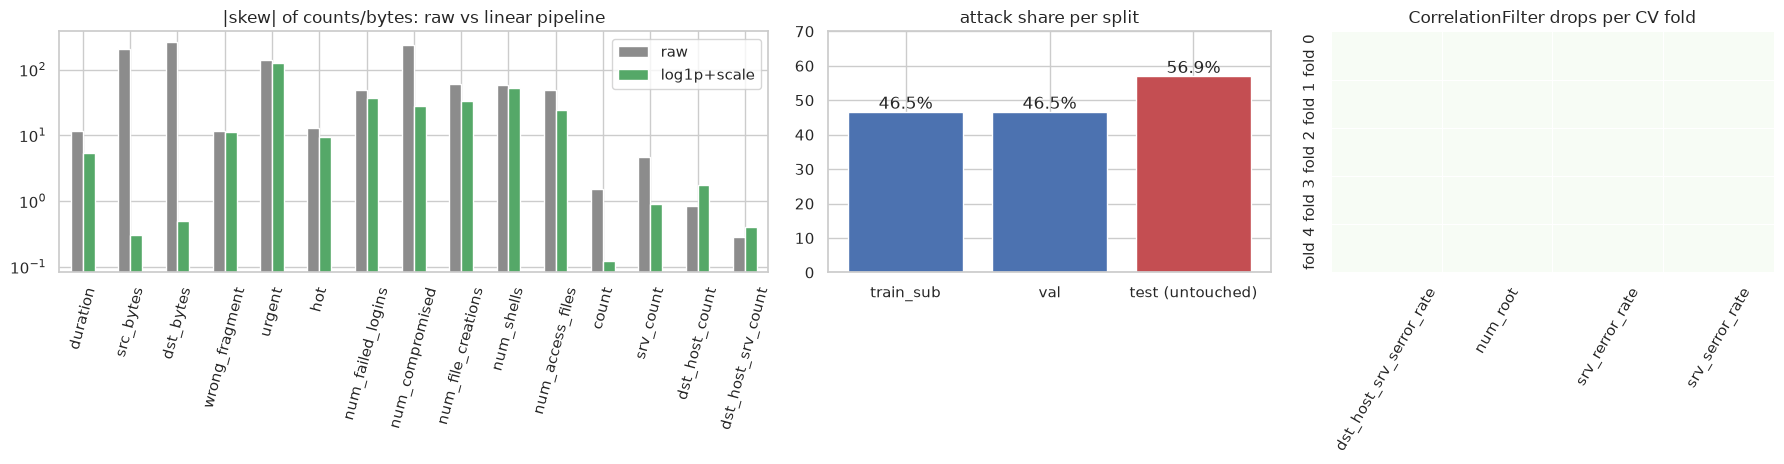

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.6, 1, 1]})
# (a) skew before/after for the log block of the linear pipeline
lin_tr = pd.DataFrame(preps["linear"].transform(X_tr), columns=preps["linear"].get_feature_names_out())
present_log = [c for c in LOG_COLS if f"log__{c}" in lin_tr.columns]
sk = pd.DataFrame({"raw": X_tr[present_log].skew(),
                   "log1p+scale": lin_tr[[f"log__{c}" for c in present_log]].skew().to_numpy()}, index=present_log)
sk.abs().plot(kind="bar", ax=axes[0], logy=True, color=["#8C8C8C", "#55A868"])
axes[0].set_title("|skew| of counts/bytes: raw vs linear pipeline"); axes[0].tick_params(axis="x", rotation=75)

# (b) stratification: attack share in each split
shares = pd.Series({"train_sub": y_tr.mean(), "val": y_va.mean(), "test (untouched)": y_te.mean()}) * 100
axes[1].bar(shares.index, shares.values, color=["#4C72B0", "#4C72B0", "#C44E52"])
for i, v in enumerate(shares.values): axes[1].text(i, v + 1, f"{v:.1f}%", ha="center")
axes[1].set_ylim(0, 70); axes[1].set_title("attack share per split")

# (c) correlation filter refit inside each CV fold: is the drop list stable?
fold_drops = []
for k, (a, _) in enumerate(ex.cv_splitter().split(X_tr, y_tr)):
    f = build_preprocessor("tree", **prep_settings).fit(X_tr.iloc[a])
    fold_drops.append(set(f.named_steps["corr"].dropped_))
allc = sorted(set().union(*fold_drops))
mat = pd.DataFrame([[c in d for c in allc] for d in fold_drops], columns=allc, index=[f"fold {i}" for i in range(5)])
sns.heatmap(mat.astype(int), cbar=False, cmap="Greens", linewidths=.5, ax=axes[2])
axes[2].set_title("CorrelationFilter drops per CV fold"); axes[2].tick_params(axis="x", rotation=60)
fig.tight_layout(); fig.savefig(FIG / "preprocessing_checks.png", dpi=110, bbox_inches="tight"); plt.show()

In [5]:
# Leakage and persistence checks
assert set(idx_tr).isdisjoint(idx_va), "train_sub and val overlap"
assert not {"label", "difficulty_level", "is_intrusion", "attack_category"} & set(X_tr.columns)
tmp = PROJECT_ROOT / "results" / "figures" / "preprocessing" / "_roundtrip.joblib"
joblib.dump(preps["linear"], tmp); re = joblib.load(tmp); tmp.unlink()
np.testing.assert_array_equal(re.transform(X_te), preps["linear"].transform(X_te))
print("✓ splits disjoint  ✓ no target/metadata columns  ✓ joblib round-trip identical  ✓ no NaN/inf")

✓ splits disjoint  ✓ no target/metadata columns  ✓ joblib round-trip identical  ✓ no NaN/inf


## 4. Feature selection — is an explicit selector beneficial?

The candidates are variance thresholding, mutual information (`SelectKBest`) and tree importance (`SelectFromModel`). Each is placed **inside** the pipeline and compared with "all features" using 3-fold CV macro-F1 on a stratified 30k subsample of `train_sub`. That keeps it cheap and leak-free.

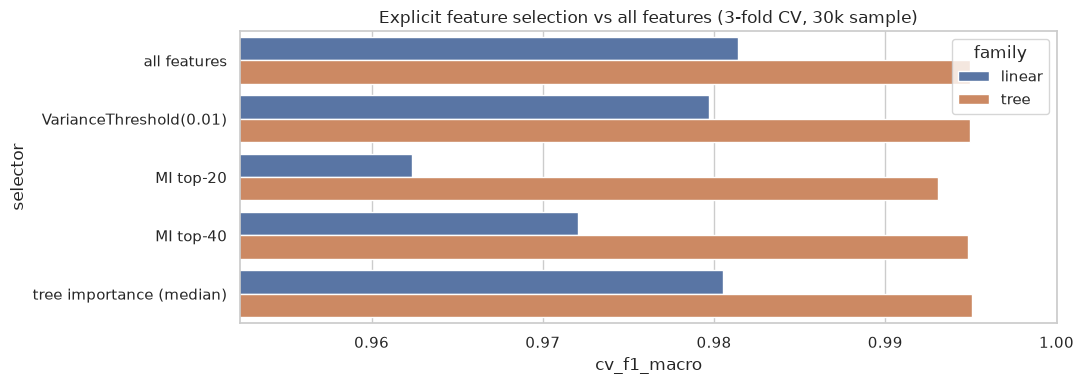

family,linear,tree
selector,,
MI top-20,0.9623,0.9931
MI top-40,0.9720,0.9948
VarianceThreshold(0.01),0.9797,0.9950
all features,0.9814,0.9950
tree importance (median),0.9805,0.9951


In [6]:
from functools import partial
from sklearn.feature_selection import SelectKBest, mutual_info_classif, VarianceThreshold, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline

sub_idx, _ = train_test_split(np.arange(len(X_tr)), train_size=30000, stratify=y_tr, random_state=SEED)
Xs, ys = X_tr.iloc[sub_idx], y_tr[sub_idx]
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
mi = partial(mutual_info_classif, random_state=SEED)
selectors = {
    "all features": "passthrough",
    "VarianceThreshold(0.01)": VarianceThreshold(0.01),
    "MI top-20": SelectKBest(mi, k=20),
    "MI top-40": SelectKBest(mi, k=40),
    "tree importance (median)": SelectFromModel(ExtraTreesClassifier(100, random_state=SEED, n_jobs=-1), threshold="median"),
}
models = {"linear": LogisticRegression(max_iter=2000, random_state=SEED),
          "tree": DecisionTreeClassifier(min_samples_leaf=5, random_state=SEED)}
res = []
for fam, est in models.items():
    for sname, sel in selectors.items():
        pipe = Pipeline([("prep", build_preprocessor(fam, **prep_settings)), ("select", sel), ("model", est)])
        s = cross_val_score(pipe, Xs, ys, cv=cv3, scoring="f1_macro", n_jobs=3)
        res.append({"family": fam, "selector": sname, "cv_f1_macro": s.mean(), "std": s.std()})
res = pd.DataFrame(res)
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=res, y="selector", x="cv_f1_macro", hue="family", ax=ax)
ax.set_xlim(res.cv_f1_macro.min() - .01, 1); ax.set_title("Explicit feature selection vs all features (3-fold CV, 30k sample)")
fig.tight_layout(); fig.savefig(FIG / "feature_selection_eval.png", dpi=110, bbox_inches="tight"); plt.show()
res.pivot(index="selector", columns="family", values="cv_f1_macro").round(4)

**Decision:** No explicit selector is added. Selecting by MI or importance does not beat "all features" within CV noise for either family. LR already gets embedded selection through L1/elastic-net regularisation (tuned), and trees select features at every split. Fewer moving parts also means fewer leakage risks.

## 5. Effect on model families

| Choice | Logistic Regression | Decision Tree / Random Forest |
|---|---|---|
| `log1p` + scaling | Needed: gradient conditioning, comparable coefficients, regularisation fairness | Not needed (split thresholds are invariant), so omitted |
| `CorrelationFilter` | Stabilises coefficients | Avoids splitting importance between twins; same columns for a fair comparison |
| OHE `min_frequency` | Fewer noisy dummies | Same encoding, as required for comparability |
| `class_weight` | Tuned | Tuned |

In [7]:
# Persist the reference fitted preprocessors (fit on train_sub) for inspection/reuse
SC = PROJECT_ROOT / CFG["artifacts"]["scalars_dir"]; SC.mkdir(exist_ok=True)
for fam, p in preps.items():
    joblib.dump(p, SC / f"preprocessor_{fam}.joblib", compress=3)
    (SC / f"preprocessor_{fam}_feature_names.json").write_text(json.dumps({
        "feature_names_out": list(map(str, p.get_feature_names_out())),
        "dropped_correlated": p.named_steps["corr"].dropped_, "dropped_constant": DROP_COLS,
        "infrequent_categories": infreq, "fit_on": "train_sub (80% stratified split of KDDTrain+, seed 42)"}, indent=2))
(SC / "label_mapping.json").write_text(json.dumps({"0": "normal", "1": "attack (any non-normal class)",
                                                   "positive_class": 1, "source_column": "class/label"}, indent=2))
sorted(p.name for p in SC.iterdir())

['label_mapping.json',
 'preprocessor_linear.joblib',
 'preprocessor_linear_feature_names.json',
 'preprocessor_tree.joblib',
 'preprocessor_tree_feature_names.json']

## 6. Risks and safeguards

- **Leakage:** every fitted step lives inside the model `Pipeline`. `cross_val_score` and Optuna refit it per fold. The test set is only transformed, never fit.
- **Prior shift:** test is 57% attack, so the threshold is chosen on validation and reported at 0.5 as well.
- **Rare-level grouping:** `min_frequency` is learned per fit, so the infrequent set can differ slightly by fold; that is expected and leak-free.
- **Serialization:** no lambdas (custom transformers are importable classes), so pipelines load with `joblib` as long as `src/` is on the path.